# Disaster Recovery Cost — Exploratory Data Analysis


In [26]:
import sys
sys.path.insert(0, '..')
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

RAW = Path('../data/raw')
PROCESSED = Path('../data/processed')

print('Libraries loaded.')

Libraries loaded.


In [27]:
decl = pd.read_csv(RAW / 'declarations.csv', low_memory=False)
pa   = pd.read_csv(RAW / 'public_assistance.csv', low_memory=False)
summ = pd.read_csv(RAW / 'disaster_summaries.csv', low_memory=False)

print(f'Declarations:       {decl.shape}')
print(f'Public Assistance:  {pa.shape}')
print(f'Disaster Summaries: {summ.shape}')

Declarations:       (69769, 10)
Public Assistance:  (152000, 9)
Disaster Summaries: (3909, 10)


In [28]:
decl.incidentType.nunique()

27

## 2. Data Quality

In [29]:
def missing_report(df, name):
    miss = df.isnull().sum()
    miss = miss[miss > 0].sort_values(ascending=False)
    pct  = (miss / len(df) * 100).round(2)
    report = pd.DataFrame({'missing': miss, 'pct': pct})
    print(f'\n--- {name} ---')
    print(report.to_string() if len(report) else 'No missing values.')

missing_report(decl, 'Declarations')
missing_report(pa,   'Public Assistance')
missing_report(summ, 'Disaster Summaries')


--- Declarations ---
                 missing   pct
incidentEndDate      537  0.77

--- Public Assistance ---
No missing values.

--- Disaster Summaries ---
                            missing    pct
totalAmountHaApproved          3364  86.06
totalAmountOnaApproved         3310  84.68
totalAmountIhpApproved         3308  84.63
iaLoadDate                     3308  84.63
totalObligatedAmountCatC2g     2361  60.40
totalObligatedAmountCatAb      1186  30.34
totalObligatedAmountHmgp       1098  28.09
totalObligatedAmountPa          925  23.66
paLoadDate                      925  23.66


In [30]:
summ.columns

Index(['disasterNumber', 'totalAmountIhpApproved', 'totalAmountHaApproved',
       'totalAmountOnaApproved', 'totalObligatedAmountPa',
       'totalObligatedAmountCatAb', 'totalObligatedAmountCatC2g',
       'totalObligatedAmountHmgp', 'paLoadDate', 'iaLoadDate'],
      dtype='object')

## 3. Target Variable: Recovery Cost Distribution
Total federal dollars obligated per disaster across all its PA-funded projects.

In [31]:
summ[['totalObligatedAmountCatC2g', 'totalObligatedAmountCatAb',
      'totalObligatedAmountHmgp', 'totalObligatedAmountPa']]

,totalObligatedAmountCatC2g,totalObligatedAmountCatAb,totalObligatedAmountHmgp,totalObligatedAmountPa
0,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,NaN,3.160623e+05,0.0,3.160623e+05
3,4.869890e+06,1.342309e+07,2710679.0,1.881275e+07
4,1.504852e+08,1.436027e+08,67665966.0,2.981058e+08
...,...,...,...,...
3904,NaN,NaN,0.0,NaN
3905,NaN,NaN,NaN,NaN
3906,NaN,NaN,0.0,NaN
3907,NaN,NaN,0.0,NaN


In [32]:
pa

,disasterNumber,stateAbbreviation,incidentType,projectAmount,federalShareObligated,totalObligated,projectSize,damageCategoryCode,applicationTitle
0,1239,TX,Severe Storm(s),100000.00,75000.00,80340.00,Large,B,(PW# 1) IMMEDIATE NEEDS FUNDING
1,1239,TX,Severe Storm(s),19685.50,14764.13,15461.00,Large,G,(PW# 5) Not Provided
2,1239,TX,Severe Storm(s),26111.00,19583.25,20507.58,Large,G,(PW# 7) Not Provided
3,1603,LA,Hurricane,18602329.78,18602329.78,18788818.15,Large,E,(PW# 18097) PROJECT MANAGEMENT FEES ON MULTIP...
4,1239,TX,Severe Storm(s),26250.83,19688.12,20617.40,Large,G,(PW# 8) Not Provided
...,...,...,...,...,...,...,...,...,...
151995,1292,NC,Hurricane,4758.06,4282.26,10207.17,Small,B,(PW# 2642) EMERGENCY PROTECTIVE MEASURES
151996,1292,NC,Hurricane,1154.56,1039.10,1079.11,Small,B,(PW# 2643) EMERGENCY PROTECTIVE MEASURES
151997,1292,NC,Hurricane,30418.08,27376.27,28124.56,Small,C,(PW# 2647) ROADS AND BRIDGES
151998,1292,NC,Hurricane,21333.72,19200.35,19725.15,Small,C,(PW# 2648) ROADS AND BRIDGES


Disasters with PA obligations: 893


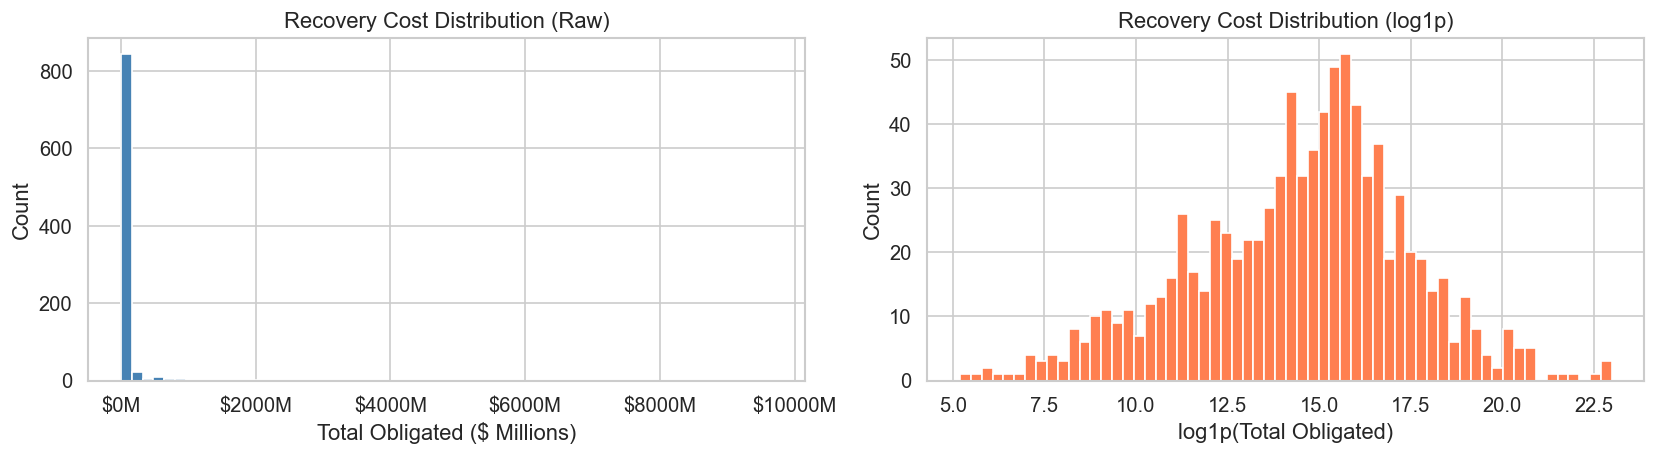

In [33]:
pa['totalObligated'] = pd.to_numeric(pa['totalObligated'], errors='coerce').fillna(0)
pa_agg = pa.groupby('disasterNumber')['totalObligated'].sum().reset_index()
pa_agg.columns = ['disasterNumber', 'total_obligated']

print(f'Disasters with PA obligations: {len(pa_agg)}')


fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Raw scale
axes[0].hist(pa_agg['total_obligated'] / 1e6, bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Recovery Cost Distribution (Raw)')
axes[0].set_xlabel('Total Obligated ($ Millions)')
axes[0].set_ylabel('Count')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))

# Log scale
axes[1].hist(np.log1p(pa_agg['total_obligated']), bins=60, color='coral', edgecolor='white')
axes[1].set_title('Recovery Cost Distribution (log1p)')
axes[1].set_xlabel('log1p(Total Obligated)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

## 4. Cost by Incident Type

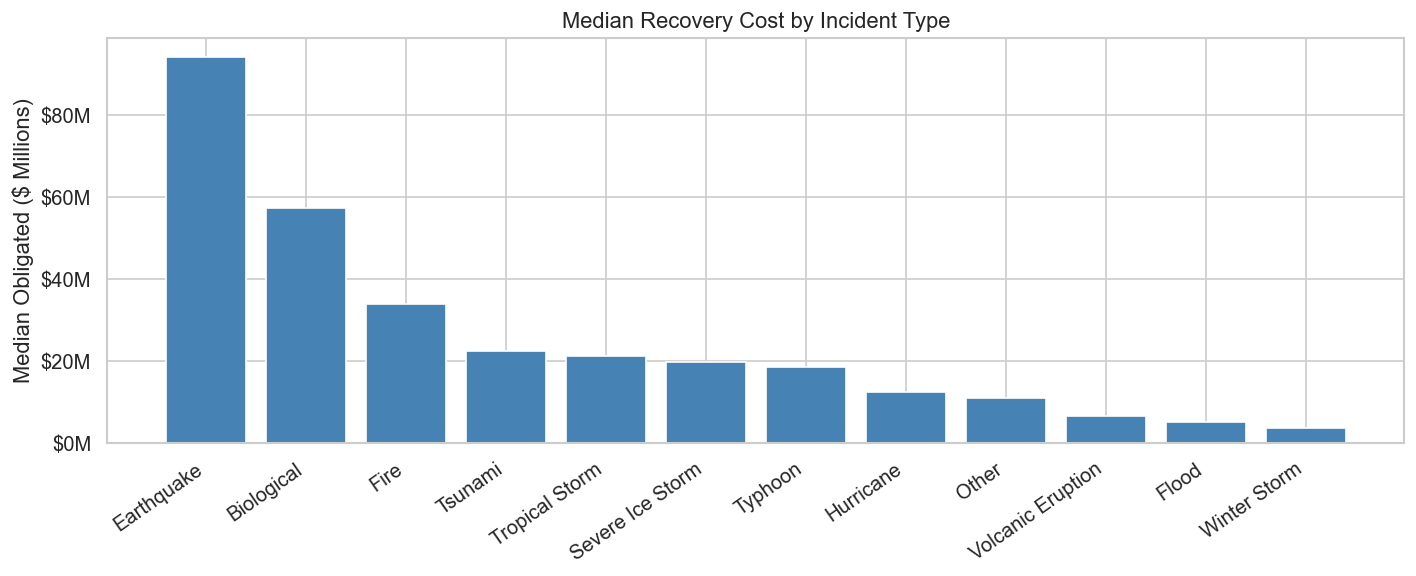

,median,mean,count
incidentType,,,
Earthquake,$94.1M,$100.9M,75
Biological,$57.3M,$856.5M,4045
Fire,$33.9M,$30.3M,227
Tsunami,$22.4M,$22.4M,6
Tropical Storm,$21.4M,$77.0M,382
Severe Ice Storm,$19.9M,$41.4M,1272
Typhoon,$18.6M,$39.1M,13
Hurricane,$12.5M,$376.8M,4280
Other,$10.9M,$14.9M,10


In [34]:
merged = decl.merge(pa_agg, on='disasterNumber', how='inner')

type_stats = (
    merged.groupby('incidentType')['total_obligated']
    .agg(['median', 'mean', 'count'])
    .sort_values('median', ascending=False)
    .head(12)
)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(type_stats.index, type_stats['median'] / 1e6, color='steelblue')
ax.set_title('Median Recovery Cost by Incident Type')
ax.set_ylabel('Median Obligated ($ Millions)')
ax.set_xlabel('')
plt.xticks(rotation=35, ha='right')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}M'))
plt.tight_layout()
plt.show()

type_stats['median'] = type_stats['median'].apply(lambda x: f'${x/1e6:.1f}M')
type_stats['mean']   = type_stats['mean'].apply(lambda x: f'${x/1e6:.1f}M')
type_stats

## 5. Geographic Analysis: Cost by State

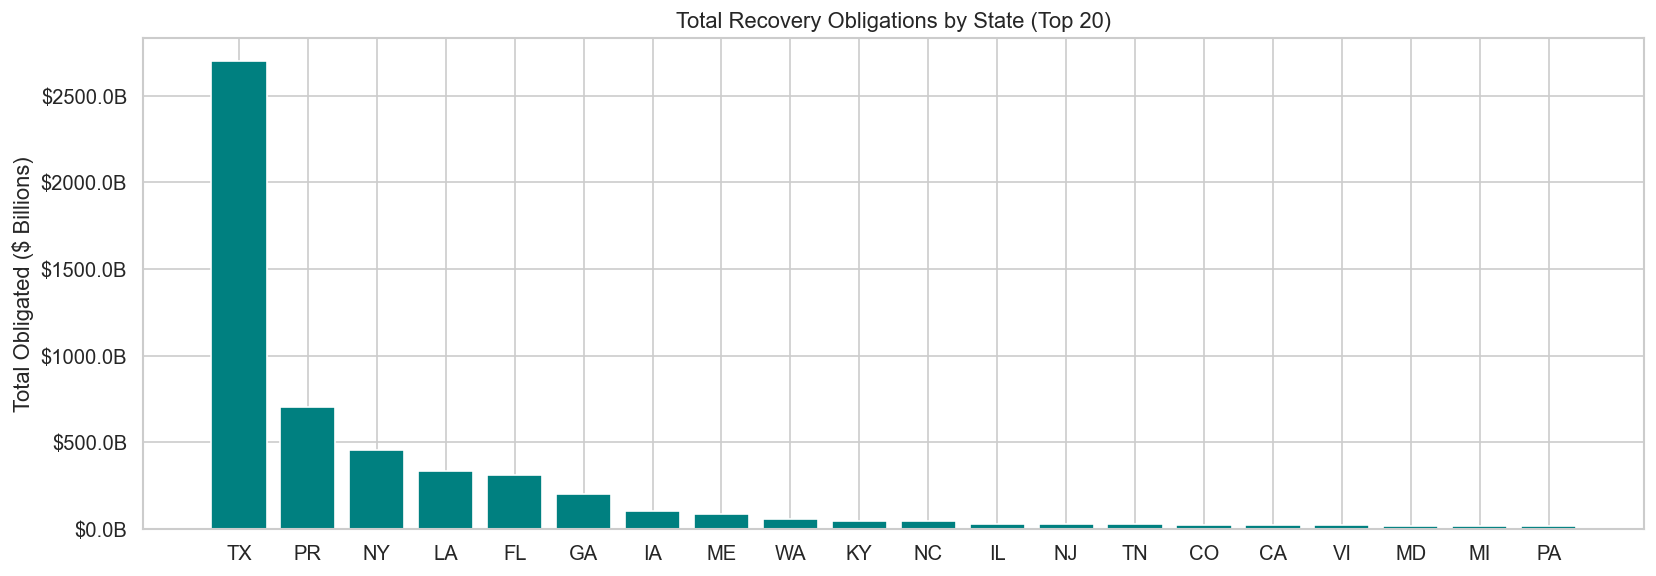

In [35]:
state_totals = (
    merged.groupby('state')['total_obligated']
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(state_totals.index, state_totals.values / 1e9, color='teal')
ax.set_title('Total Recovery Obligations by State (Top 20)')
ax.set_ylabel('Total Obligated ($ Billions)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}B'))
plt.tight_layout()
plt.show()

## 6. Temporal Trends

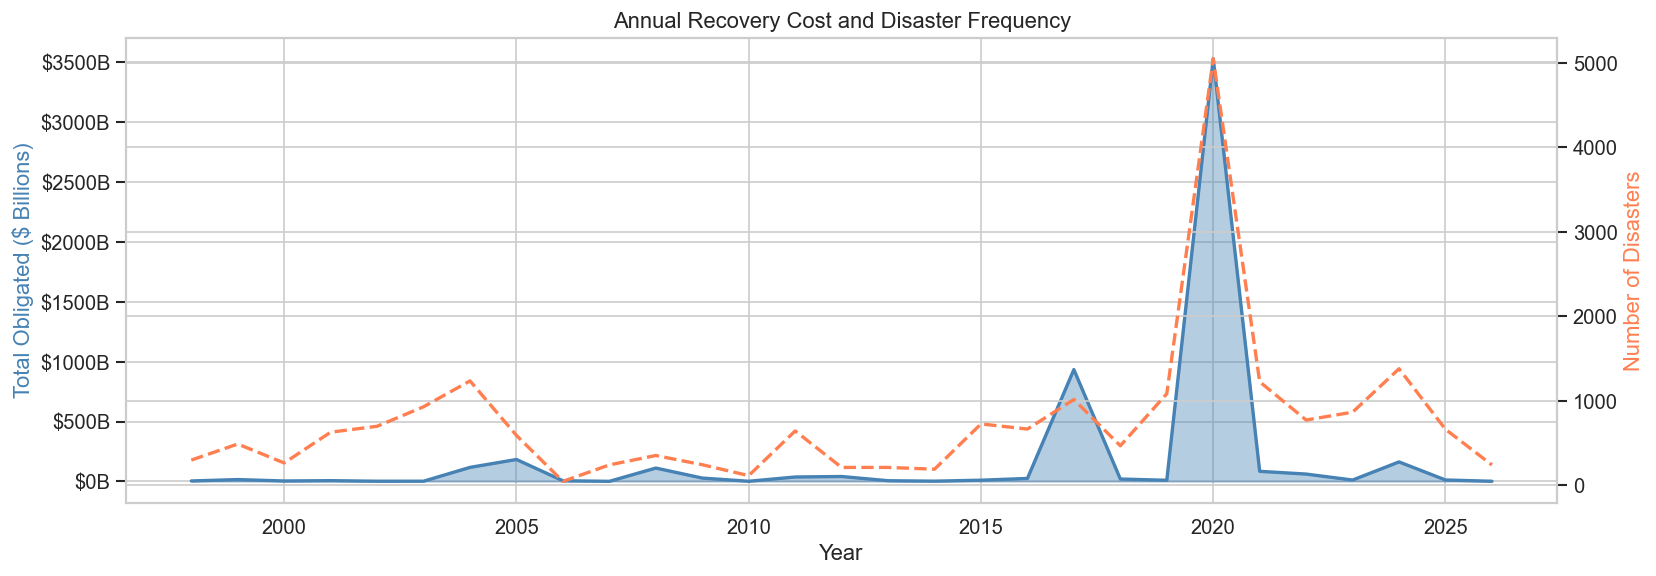

In [36]:
merged['declarationDate'] = pd.to_datetime(merged['declarationDate'], errors='coerce', utc=True)
merged['year'] = merged['declarationDate'].dt.year

yearly = merged.groupby('year').agg(
    total_cost=('total_obligated', 'sum'),
    disaster_count=('disasterNumber', 'count'),
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

ax1.fill_between(yearly['year'], yearly['total_cost'] / 1e9, alpha=0.4, color='steelblue')
ax1.plot(yearly['year'], yearly['total_cost'] / 1e9, color='steelblue', lw=2)
ax2.plot(yearly['year'], yearly['disaster_count'], color='coral', lw=2, linestyle='--')

ax1.set_xlabel('Year')
ax1.set_ylabel('Total Obligated ($ Billions)', color='steelblue')
ax2.set_ylabel('Number of Disasters', color='coral')
ax1.set_title('Annual Recovery Cost and Disaster Frequency')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}B'))
plt.tight_layout()
plt.show()

## 7. Feature Correlations

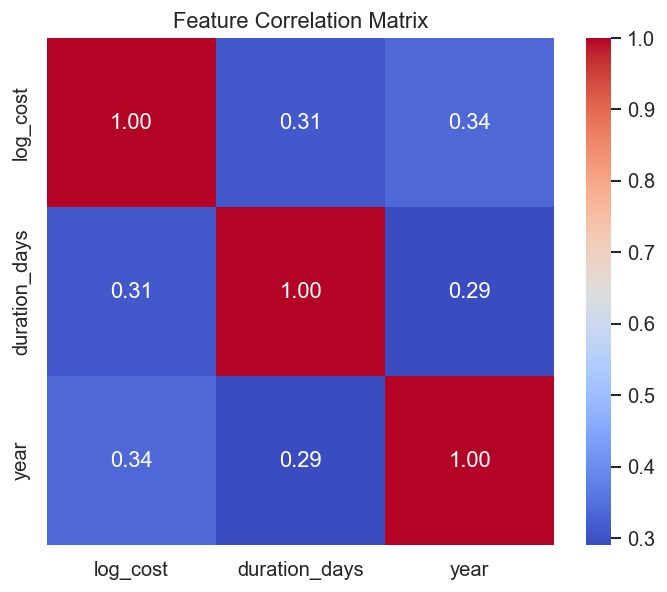

In [37]:
# Parse and engineer basic numeric features for correlation
merged['incidentBeginDate'] = pd.to_datetime(merged['incidentBeginDate'], errors='coerce', utc=True)
merged['incidentEndDate']   = pd.to_datetime(merged['incidentEndDate'],   errors='coerce', utc=True)
merged['duration_days'] = (merged['incidentEndDate'] - merged['incidentBeginDate']).dt.days.clip(lower=0)
merged['log_cost'] = np.log1p(merged['total_obligated'])

corr_cols = ['log_cost', 'duration_days', 'year']
corr_df = merged[corr_cols].dropna()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax, square=True)
ax.set_title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

## 8. Outlier Detection

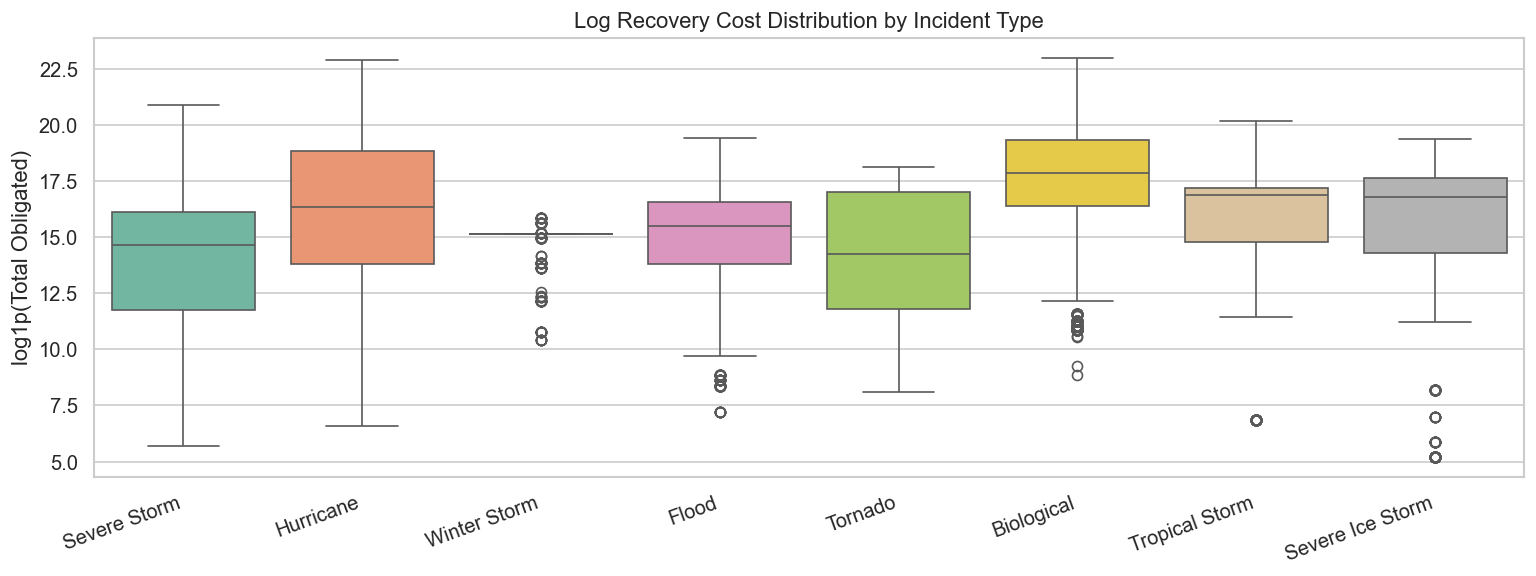

In [38]:
# Boxplot of log cost by top 8 incident types
top_types = merged['incidentType'].value_counts().head(8).index
plot_df = merged[merged['incidentType'].isin(top_types)]

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(data=plot_df, x='incidentType', y='log_cost', ax=ax, palette='Set2')
ax.set_title('Log Recovery Cost Distribution by Incident Type')
ax.set_ylabel('log1p(Total Obligated)')
ax.set_xlabel('')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()